# Telecom customer churn: tree models and SHAP
**CHS2406 Data-driven AI · Week 05, Lecture 02 · Final-year BSc · Student practical**

| Section | Time | Exact slides in Week05_Lecture02_Machine_Learning_Models_XAI_ChatGPT.pptx | Activity |
|---|---:|---|---|
| Provided setup and data | 5 min | Practical preparation; no dedicated slide | Load data, inspect classes, use the supplied split and encoding |
| Exercise 1: Decision Tree | 7 min | **2–11**: Decision Tree, tree structure, classification, impurity and hyperparameters | Fit a shallow tree and inspect its rules |
| Exercise 2: Random Forest | 5 min | **12**: Random Forest | Fit a forest and obtain churn probabilities |
| Exercise 3: XGBoost | 5 min | **13**, XGBoost box | Fit a boosted-tree classifier |
| Exercise 4: CatBoost | 5 min | **13**, CatBoost box | Fit a CatBoost classifier |
| Exercise 5: LightGBM | 5 min | **13**, LightGBM box | Fit a LightGBM classifier |
| Exercise 6: Compare models and final check | 6 min | **12–13** for the models; metric comparison is a practical extension | Compare validation scores, then evaluate the selected model once on test data |
| Exercise 7: Decision Tree importance | 7 min | **14–15**: Feature Importance & XAI; Feature Importance (Decision Tree) | Plot the tree's built-in feature importance |
| Exercise 8: SHAP for XGBoost | 15 min | **14 and 16**: XAI and SHAP | Explain churn probabilities using four SHAP plots |
| Optional A: Tree complexity | Extra | **2 and 11** | Compare tree depths using training and validation scores |
| Optional B: Native categorical CatBoost | Extra | **13**, CatBoost box | Fit directly with categorical columns |
| Optional C: Classification threshold | Extra | Practical extension; no threshold slide in this deck | Explore precision, recall and F1 at different thresholds |
| Optional D: SHAP reference customers | Extra | **16**, reference homes/baseline panels | Change the background and inspect the explanation |

**Core total: 60 minutes.** Slide numbers are PowerPoint positions, including the title slide. Slide 17 is the closing slide. Slide 16 uses house-price regression; this practical extends SHAP to a classification probability.

Work through Exercises 1–8. If time is up, skip the optional activities and run the **Final test check** near the bottom. Each model exercise has three small coding tasks: create, fit and obtain positive-class probabilities.

## Scenario and learning goals
A telecom company wants to identify customers associated with churn in its sample data.
**Churn = the customer left.** We encode **1 = Churn** and **0 = No churn** throughout.

Use IBM's public Telco sample dataset: **7,043 customers**. This is sample data for teaching, rather than a prospective study of future cancellations. We select nine readable inputs to keep the hour focused.

By the end you will have compared five classifiers, inspected a tree's importance scores and explained one XGBoost prediction. There is no assumed winning algorithm.

## Setup: run once before importing the libraries
Open in **Google Colab**, choose a CPU runtime and run this cell first. No GPU or API key is needed.
If Colab requests a restart after installation, restart the session and continue with the imports.
Installation and the first dataset download need internet access.

In [1]:
%pip install --quiet "xgboost==3.0.5" "catboost==1.2.8" "lightgbm==4.6.0" "shap==0.49.1"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, xgboost, catboost, lightgbm, shap
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

SEED = 42
THRESHOLD = 0.50
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'figure.dpi': 110,
    'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
BLUE, TEAL, ORANGE = '#246DB2', '#087F86', '#D77510'
print(f'scikit-learn {sklearn.__version__} | XGBoost {xgboost.__version__}')
print(f'CatBoost {catboost.__version__} | LightGBM {lightgbm.__version__} | SHAP {shap.__version__}')

scikit-learn 1.8.0 | XGBoost 3.0.5
CatBoost 1.2.8 | LightGBM 4.6.0 | SHAP 0.49.1


## Provided data preparation
Run the next three cells. They handle loading, splitting and encoding so you can spend your time on the models.

| Input | Meaning |
|---|---|
| tenure | Months with the company |
| MonthlyCharges | Monthly bill, in dollars |
| TotalCharges | Total amount billed, in dollars |
| Contract | Month-to-month, one year or two years |
| InternetService | Internet service type |
| TechSupport | Technical support service |
| OnlineSecurity | Online security service |
| PaymentMethod | Payment method |
| PaperlessBilling | Whether billing is paperless |

The original CSV has other columns. We select the nine above before comparing models and leave the identifier out of the predictors.
The cell downloads the file automatically if needed. If download is unavailable, upload the accompanying **Telco_Customer_Churn.csv** into Colab's Files panel and rerun it.

,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,TechSupport,OnlineSecurity,PaymentMethod,PaperlessBilling,Churn
0,1,29.85,29.85,Month-to-month,DSL,No,No,Electronic check,Yes,No
1,34,56.95,1889.5,One year,DSL,No,Yes,Mailed check,No,No
2,2,53.85,108.15,Month-to-month,DSL,No,Yes,Mailed check,Yes,Yes
3,45,42.30,1840.75,One year,DSL,Yes,Yes,Bank transfer (automatic),No,No
4,2,70.70,151.65,Month-to-month,Fiber optic,No,No,Electronic check,Yes,Yes


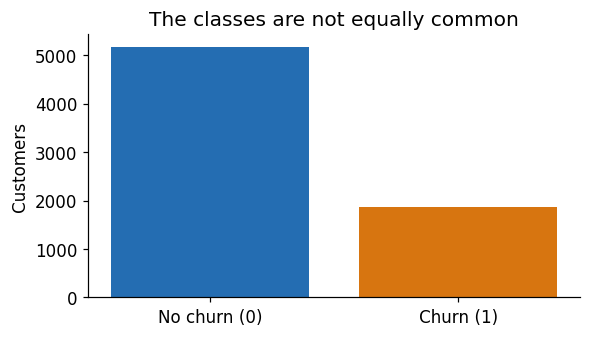

7,043 customers | Churn: 1,869 (26.5%)
Missing TotalCharges values: 11


In [3]:
DATA_FILE = Path('Telco_Customer_Churn.csv')
DATA_URL = ('https://raw.githubusercontent.com/IBM/'
            'telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv')
if not DATA_FILE.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)
data = pd.read_csv(DATA_FILE)

NUMERIC = ['tenure', 'MonthlyCharges', 'TotalCharges']
CATEGORICAL = ['Contract', 'InternetService', 'TechSupport',
               'OnlineSecurity', 'PaymentMethod', 'PaperlessBilling']
FEATURES = NUMERIC + CATEGORICAL
X = data[FEATURES].copy()
X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
y = data['Churn'].map({'No': 0, 'Yes': 1}).rename('Churn')
assert len(data) == 7043 and y.notna().all()
display(data[FEATURES + ['Churn']].head())
print(f'{len(data):,} customers | Churn: {y.sum():,} ({y.mean():.1%})')
print(f'Missing TotalCharges values: {X.TotalCharges.isna().sum()}')

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.bar(['No churn (0)', 'Churn (1)'], [(y == 0).sum(), (y == 1).sum()],
       color=[BLUE, ORANGE])
ax.set(ylabel='Customers', title='The classes are not equally common')
fig.tight_layout()
plt.show()

**Three separate sets:** 60% training, 20% validation and 20% test, with stratification to preserve the class proportions.
Fit models and preprocessing using training data. Compare configurations using validation data.
Open the test results only after selecting the best observed core model.

In [4]:
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), NUMERIC),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False,
                          dtype=np.float32), CATEGORICAL),
], verbose_feature_names_out=False)

train_array = preprocessor.fit_transform(X_train)  # fit only on training data
feature_names = list(preprocessor.get_feature_names_out())
X_train_ready = pd.DataFrame(train_array, columns=feature_names,
                            index=X_train.index).astype(np.float32)
X_valid_ready = pd.DataFrame(preprocessor.transform(X_valid), columns=feature_names,
                            index=X_valid.index).astype(np.float32)
X_test_ready = pd.DataFrame(preprocessor.transform(X_test), columns=feature_names,
                           index=X_test.index).astype(np.float32)

encoder = preprocessor.named_transformers_['cat']
source_names = NUMERIC + [column for column, categories in
    zip(CATEGORICAL, encoder.categories_) for _ in categories]
feature_to_source = pd.Series(source_names, index=feature_names)
print(f'Train: {len(X_train):,} | Validation: {len(X_valid):,} | Test: {len(X_test):,}')
print(f'{len(FEATURES)} original inputs become {len(feature_names)} encoded columns.')
display(X_train_ready.head(3).round(2))

,tenure,MonthlyCharges,TotalCharges,Contract_Month-to-month,Contract_One year,Contract_Two year,InternetService_DSL,InternetService_Fiber optic,InternetService_No,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,PaperlessBilling_No,PaperlessBilling_Yes
2312,18.0,20.100000,401.850006,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
5227,7.0,96.199997,639.700012,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
6404,52.0,109.300003,5731.399902,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0


Train: 4,225 | Validation: 1,409 | Test: 1,409
9 original inputs become 21 encoded columns.


All five core classifiers receive the **same encoded inputs and splits**. A category such as `Contract_Month-to-month` is an indicator: **1 = present, 0 = absent**.
Numeric missing values use the training median. Tree models need no feature scaling here.
CatBoost's native categorical handling is available as Optional B.

## Provided evaluation helper and baseline
We use a **0.50 threshold** for every core model. `predict_proba(... )[:, 1]` returns the probability of **Churn = 1**.

| Metric | Interpretation |
|---|---|
| Accuracy | Fraction of all customers classified correctly |
| Precision | Of predicted churners, the fraction that actually churned |
| Recall | Of actual churners, the fraction identified |
| F1 | Harmonic mean of churn precision and recall; our primary comparison metric |
| ROC-AUC | Ranking ability across thresholds; uses probabilities |

Higher is better for these metrics. The dummy model always predicts the majority class at the 0.50 threshold. Check its accuracy **and** its F1.

In [5]:
EXPECTED_MODELS = ['Decision Tree', 'Random Forest', 'XGBoost', 'CatBoost', 'LightGBM']
models, validation_results = {}, {}

def score_probabilities(labels, probability, threshold=0.50):
    probability = np.asarray(probability)
    assert probability.shape == (len(labels),)
    assert np.isfinite(probability).all() and ((probability >= 0) & (probability <= 1)).all()
    prediction = (probability >= threshold).astype(int)
    return {'Accuracy': accuracy_score(labels, prediction),
            'Precision': precision_score(labels, prediction, zero_division=0),
            'Recall': recall_score(labels, prediction, zero_division=0),
            'F1': f1_score(labels, prediction, zero_division=0),
            'ROC-AUC': roc_auc_score(labels, probability)}

def save_validation_result(name, fitted_model, probability, fit_seconds):
    assert np.array_equal(fitted_model.classes_, [0, 1])
    scores = score_probabilities(y_valid, probability, THRESHOLD)
    models[name] = fitted_model
    validation_results[name] = {**scores, 'Fit seconds': fit_seconds}
    display(pd.DataFrame([validation_results[name]], index=[name]).round(4))

dummy = DummyClassifier(strategy='prior').fit(X_train_ready, y_train)
dummy_scores = score_probabilities(y_valid, dummy.predict_proba(X_valid_ready)[:, 1])
display(pd.DataFrame([dummy_scores], index=['Majority-class baseline']).round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC
Majority-class baseline,0.7346,0.0,0.0,0.0,0.5


## Exercise 1 · Decision Tree (7 minutes)
**Slides 2–11.** Complete the three tasks: create a classifier, fit it on the training data and obtain validation probabilities for class 1.

Use `DecisionTreeClassifier` with `max_depth=3`, `min_samples_leaf=25` and `random_state=SEED`.
Run the supplied cell below your implementation to inspect the fitted tree.

**Question:** what does a leaf's class distribution tell you about its prediction?

In [6]:
# TODO 1: create the Decision Tree classifier using the settings above.
dt_model = None

started = time.perf_counter()
# TODO 2: fit dt_model on X_train_ready and y_train.
dt_fit_seconds = time.perf_counter() - started

# TODO 3: obtain predict_proba on X_valid_ready and select column 1.
dt_valid_probability = None

if dt_model is not None and dt_valid_probability is not None:
    save_validation_result('Decision Tree', dt_model, dt_valid_probability, dt_fit_seconds)
else:
    print('Complete the three TODOs in Exercise 1, then rerun this cell.')

Complete the three TODOs in Exercise 1, then rerun this cell.


In [7]:
if 'Decision Tree' in models:
    fig, ax = plt.subplots(figsize=(20, 8))
    plot_tree(models['Decision Tree'], feature_names=feature_names,
              class_names=['No churn', 'Churn'], filled=True,
              rounded=True, fontsize=8, ax=ax)
    ax.set_title('The complete fitted tree (maximum depth 3)')
    plt.show()
else:
    print('Fit the Decision Tree in Exercise 1 to display its rules.')

Fit the Decision Tree in Exercise 1 to display its rules.


## Exercise 2 · Random Forest (5 minutes)
**Slide 12.** Repeat the create–fit–predict workflow using `RandomForestClassifier`.
Use 150 trees, `max_depth=8`, `min_samples_leaf=5`, `max_features='sqrt'`, `n_jobs=2` and `random_state=SEED`.

**Question:** why can different trees in the forest make different predictions?

In [8]:
# TODO 1: create the Random Forest classifier using the settings above.
rf_model = None

started = time.perf_counter()
# TODO 2: fit rf_model on X_train_ready and y_train.
rf_fit_seconds = time.perf_counter() - started

# TODO 3: obtain predict_proba on X_valid_ready and select column 1.
rf_valid_probability = None

if rf_model is not None and rf_valid_probability is not None:
    save_validation_result('Random Forest', rf_model, rf_valid_probability, rf_fit_seconds)
else:
    print('Complete the three TODOs in Exercise 2, then rerun this cell.')

Complete the three TODOs in Exercise 2, then rerun this cell.


## Exercise 3 · XGBoost (5 minutes)
**Slide 13, XGBoost box.** Use `XGBClassifier` with the following settings:
`n_estimators=150`, `max_depth=3`, `learning_rate=0.08`, `subsample=0.9`,
`colsample_bytree=0.9`, `objective='binary:logistic'`, `eval_metric='logloss'`,
`tree_method='hist'`, `n_jobs=2`, `random_state=SEED`.

Fit the model and save its validation churn probabilities. We will explain this same fitted model in Exercise 8.

In [9]:
# TODO 1: create the XGBoost classifier using the settings above.
xgb_model = None

started = time.perf_counter()
# TODO 2: fit xgb_model on X_train_ready and y_train.
xgb_fit_seconds = time.perf_counter() - started

# TODO 3: obtain predict_proba on X_valid_ready and select column 1.
xgb_valid_probability = None

if xgb_model is not None and xgb_valid_probability is not None:
    save_validation_result('XGBoost', xgb_model, xgb_valid_probability, xgb_fit_seconds)
else:
    print('Complete the three TODOs in Exercise 3, then rerun this cell.')

Complete the three TODOs in Exercise 3, then rerun this cell.


## Exercise 4 · CatBoost (5 minutes)
**Slide 13, CatBoost box.** Use `CatBoostClassifier` with `iterations=150`, `depth=5`,
`learning_rate=0.08`, `loss_function='Logloss'`, `verbose=False`,
`allow_writing_files=False`, `thread_count=2` and `random_seed=SEED`.

CatBoost calls its tree-count setting `iterations`. Use the same encoded training and validation data as the other core models.

In [10]:
# TODO 1: create the CatBoost classifier using the settings above.
cat_model = None

started = time.perf_counter()
# TODO 2: fit cat_model on X_train_ready and y_train.
cat_fit_seconds = time.perf_counter() - started

# TODO 3: obtain predict_proba on X_valid_ready and select column 1.
cat_valid_probability = None

if cat_model is not None and cat_valid_probability is not None:
    save_validation_result('CatBoost', cat_model, cat_valid_probability, cat_fit_seconds)
else:
    print('Complete the three TODOs in Exercise 4, then rerun this cell.')

Complete the three TODOs in Exercise 4, then rerun this cell.


## Exercise 5 · LightGBM (5 minutes)
**Slide 13, LightGBM box.** Use `LGBMClassifier` with `n_estimators=150`, `max_depth=5`,
`num_leaves=15`, `learning_rate=0.08`, `subsample=0.9`, `subsample_freq=1`,
`colsample_bytree=0.9`, `min_child_samples=20`, `n_jobs=2`, `verbosity=-1` and `random_state=SEED`.

Fit the model and obtain validation churn probabilities. These settings are starting configurations, not individually tuned optima.

In [11]:
# TODO 1: create the LightGBM classifier using the settings above.
lgb_model = None

started = time.perf_counter()
# TODO 2: fit lgb_model on X_train_ready and y_train.
lgb_fit_seconds = time.perf_counter() - started

# TODO 3: obtain predict_proba on X_valid_ready and select column 1.
lgb_valid_probability = None

if lgb_model is not None and lgb_valid_probability is not None:
    save_validation_result('LightGBM', lgb_model, lgb_valid_probability, lgb_fit_seconds)
else:
    print('Complete the three TODOs in Exercise 5, then rerun this cell.')

Complete the three TODOs in Exercise 5, then rerun this cell.


## Exercise 6 · Compare the algorithms (6 minutes, including the final check)
**Slides 12–13 introduce the models; the comparison procedure is a practical extension.**

1. Complete all five model exercises, then run the comparison table and chart.
2. Identify the highest validation **F1**. Use ROC-AUC only to break an exact F1 tie.
3. Explain whether the differences are large enough to make a strong conclusion.

The supplied ranking uses **validation data**. All models share the same training customers, inputs and 0.50 threshold. Their configurations are fixed starting points. This comparison identifies the best observed configuration here, rather than a universally best algorithm.

In [12]:
core_winner_name = None
if all(name in validation_results for name in EXPECTED_MODELS):
    comparison = pd.DataFrame(validation_results).T
    comparison = comparison.loc[EXPECTED_MODELS].sort_values(
        ['F1', 'ROC-AUC'], ascending=[False, False], kind='stable')
    display(comparison.round(4))
    core_winner_name = comparison.index[0]
    print(f'Best observed validation F1: {core_winner_name} '
          f'({comparison.iloc[0]["F1"]:.4f})')

    chart = comparison[['F1', 'ROC-AUC']].copy()
    chart.loc['Majority-class baseline'] = [dummy_scores['F1'], dummy_scores['ROC-AUC']]
    ax = chart.plot.barh(color=[BLUE, TEAL], figsize=(10, 5), width=0.75)
    ax.invert_yaxis()
    ax.set(xlim=(0, 1), xlabel='Validation score',
           title='Compare F1 and ROC-AUC on the same validation customers')
    ax.legend(loc='lower right')
    plt.tight_layout()
    plt.show()
else:
    missing = [name for name in EXPECTED_MODELS if name not in validation_results]
    print('Complete these core models first:', ', '.join(missing))

Complete these core models first: Decision Tree, Random Forest, XGBoost, CatBoost, LightGBM


Keep the selected model fixed. The **Final test check** is after the SHAP and optional sections, so the test set stays unopened while you work through the explanations.

**Write your answer:** which model ranks first on F1? Does the same model rank first on ROC-AUC? Why is the dummy model's accuracy misleading on its own?

## Exercise 7 · Decision Tree feature importance (7 minutes)
**Slides 14–15.** Extract the fitted Decision Tree's `feature_importances_` and create a Series indexed by `feature_names`.
The plotting cell groups indicators back to the nine original inputs and plots their total importance.

Built-in importance sums sample-weighted impurity reductions from splits using each feature, then normalises the totals. These are Gini reductions for this classifier.
A feature used at several nodes receives the combined score. Features unused by this tree receive zero.

**Question:** which three original inputs are most important in this tree? Do importance scores tell you whether an input raises or lowers a particular customer's probability?

In [13]:
dt_importance = None
if 'Decision Tree' in models:
    # TODO: replace None with a pandas Series built from the fitted tree's
    # feature_importances_, using feature_names as its index.
    pass
else:
    print('Complete Exercise 1 first.')

Complete Exercise 1 first.


In [14]:
if dt_importance is not None:
    importance_by_input = dt_importance.groupby(feature_to_source).sum().sort_values()
    assert np.isclose(importance_by_input.sum(), 1)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    bars = ax.barh(importance_by_input.index, 100 * importance_by_input.values, color=BLUE)
    ax.bar_label(bars, labels=[f'{100*v:.1f}%' for v in importance_by_input], padding=4)
    ax.set(xlabel='Share of training impurity reduction (%)',
           title='Decision Tree: built-in feature importance')
    ax.set_xlim(0, max(1, 100 * importance_by_input.max()) * 1.2)
    fig.tight_layout()
    plt.show()
    display(importance_by_input.sort_values(ascending=False).to_frame().round(4))
else:
    print('Extract the feature importances in Exercise 7 to draw the plot.')

Extract the feature importances in Exercise 7 to draw the plot.


## Exercise 8 · Explain XGBoost with SHAP (15 minutes)
**Slides 14 and 16.** Explain the same fitted XGBoost classifier, even if another model led the comparison.

**Important settings:** `model_output='probability'` and `feature_perturbation='interventional'`, with explicit reference data.
They make the output the model's estimated probability of **Churn = 1**.

$$P(\mathrm{Churn}=1\mid x)=\mathrm{baseline}+\sum_j\phi_j(x)$$

Choose 100 training customers as the background and explain 150 validation customers. The baseline is the average **model prediction** on the reference customers.
In the supplied plotting conversion, probabilities are multiplied by 100: a SHAP value of **+5 means +5 percentage points**, not a 5% relative increase.

**A. Complete two lines:** construct `shap.TreeExplainer` with the settings above and evaluate it on `X_shap`.

In [15]:
background = X_train_ready.sample(n=100, random_state=SEED)
X_shap = X_valid_ready.sample(n=150, random_state=SEED)
shap_values, shap_pp = None, None

if 'XGBoost' in models:
    # TODO: create a TreeExplainer for models['XGBoost'], using background,
    # model_output='probability' and feature_perturbation='interventional'.
    xgb_explainer = None
    # TODO: evaluate xgb_explainer on X_shap and store the Explanation.
    shap_values = None
else:
    print('Complete Exercise 3 first.')

Complete Exercise 3 first.


In [16]:
if shap_values is not None:
    xgb_probability = models['XGBoost'].predict_proba(X_shap)[:, 1]
    reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
    np.testing.assert_allclose(reconstructed, xgb_probability, rtol=0, atol=1e-5)
    np.testing.assert_allclose(
        float(shap_values.base_values[0]),
        models['XGBoost'].predict_proba(background)[:, 1].mean(), atol=1e-6)
    shap_pp = shap.Explanation(values=100 * shap_values.values,
        base_values=100 * shap_values.base_values, data=shap_values.data,
        feature_names=feature_names)
    print(f'Baseline churn probability: {shap_pp.base_values[0]:.2f}%')
    print('Checked: baseline + SHAP contributions = probability for all 150 customers.')
else:
    print('Create the SHAP Explanation in Exercise 8A first.')

Create the SHAP Explanation in Exercise 8A first.


**B. Global bar plot.** Call `shap.plots.bar(shap_pp, max_display=10)`.
It displays mean **absolute** contributions across the explained customers. A large bar means large average influence, in either direction.

In [17]:
if shap_pp is not None:
    # TODO: draw the global SHAP bar plot using shap_pp.
    pass
else:
    print('Complete Exercise 8A first.')

Complete Exercise 8A first.


**C. Beeswarm plot.** Call `shap.plots.beeswarm(shap_pp, max_display=10)`.
Each dot is one customer. Right means a contribution towards a higher churn probability; left means a contribution towards a lower one.
Red shows a high feature value and blue a low value. For a category indicator, high means **1 = category present**.

**Question:** how does short tenure tend to contribute to these model predictions?

In [18]:
if shap_pp is not None:
    # TODO: draw the SHAP beeswarm plot using shap_pp.
    pass
else:
    print('Complete Exercise 8A first.')

Complete Exercise 8A first.


**D. Dependence plot.** Use `shap.plots.scatter(shap_pp[:, 'tenure'])`.
The horizontal axis shows tenure in months; the vertical axis shows that input's SHAP contribution in percentage points.
Customers with similar tenure can have different contributions because the model also uses other inputs.

In [19]:
if shap_pp is not None:
    # TODO: plot the tenure column of shap_pp with shap.plots.scatter.
    pass
else:
    print('Complete Exercise 8A first.')

Complete Exercise 8A first.


**E. One customer's prediction.** For the worked example, choose the customer whose predicted probability is closest to 65% among the 150 explained customers.
Inspect the actual input values and the arithmetic, then call `shap.plots.waterfall(local_pp, max_display=10)`.
The waterfall's red/blue colours show positive/negative contribution direction.

In [20]:
local_pp = None
if shap_pp is not None:
    CUSTOMER_POSITION = int(np.argmin(np.abs(xgb_probability - 0.65)))  # try another position, 0–149
    customer_index = X_shap.index[CUSTOMER_POSITION]
    local_pp = shap_pp[CUSTOMER_POSITION]
    predicted_percent = 100 * float(xgb_probability[CUSTOMER_POSITION])
    observed_label = 'Churn' if y_valid.loc[customer_index] == 1 else 'No churn'
    display(X_valid.loc[[customer_index]].T.rename(columns={customer_index: 'Customer value'}))
    print(f'Predicted churn probability: {predicted_percent:.2f}% | Observed label: {observed_label}')
    print(f'{float(local_pp.base_values):.2f}% baseline + '
          f'({local_pp.values.sum():+.2f} percentage points) = {predicted_percent:.2f}%')
    contributions = pd.Series(local_pp.values, index=feature_names)
    display(contributions.reindex(contributions.abs().sort_values(ascending=False).index)
            .head(6).to_frame('SHAP contribution (percentage points)').round(2))
else:
    print('Complete Exercise 8A first.')

Complete Exercise 8A first.


In [21]:
if local_pp is not None:
    # TODO: draw a waterfall for this single customer's local_pp Explanation.
    pass
else:
    print('Create the local explanation in the previous cell first.')

Create the local explanation in the previous cell first.


**Write your explanation:** name one input that pushes this customer's churn probability up, one that pushes it down, and explain the baseline.

The explanation keeps this customer's actual feature values fixed. It explains the trained model, rather than proving why the person left or what a retention offer would cause.
Encoded categorical indicators and related inputs can affect how contributions are shared. SHAP's background replacement can produce less likely input combinations.

**Compare the explanations:** Decision Tree importance is a share of training impurity reduction. The SHAP bar shows mean absolute probability contributions in percentage points. Their rankings can be compared qualitatively; the numerical scores use different units.

## Optional activities
Start these only after completing the core exercises. Use training and validation data for these explorations.
Keep the original five core models and their comparison unchanged: the final test check below evaluates the original core winner at the original 0.50 threshold.

### Optional A · Tree complexity
**Slides 2 and 11.** Fit Decision Trees with depths `[1, 2, 3, 5, 8, None]`.
Plot training F1 and validation F1 against depth. Does a better training score always give a better validation score?
Keep `min_samples_leaf=5` and `random_state=SEED` fixed.

In [22]:
# TODO: fit the six tree configurations and collect training and validation F1.
# Use separate variable names so you keep the original core tree unchanged.
# TODO: plot the two score curves and interpret the difference.

### Optional B · CatBoost with native categorical inputs
**Slide 13.** Fit CatBoost on the nine original input columns, passing `cat_features=CATEGORICAL`.
Fill missing numeric values using **training medians**, keep categorical values as strings, and compare its validation F1 with the encoded CatBoost model.
Use the same CatBoost settings as Exercise 4. More suitable handling of categories is a possibility, not a guaranteed improvement on every split.

In [23]:
# TODO: prepare raw training and validation frames using training-only medians.
# TODO: fit a separate CatBoostClassifier with cat_features=CATEGORICAL.
# TODO: compare validation scores without changing models['CatBoost'].

### Optional C · Change the decision threshold
**Practical extension.** For the core XGBoost model, evaluate thresholds from 0.10 to 0.90 in steps of 0.05 on validation data.
Plot precision, recall and F1. Identify the threshold with the highest validation F1 and explain the precision–recall trade-off.
Changing a threshold does not retrain the classifier. Keep this exploration separate from the original core comparison.

In [24]:
# TODO: reuse the core XGBoost validation probabilities across thresholds.
# TODO: calculate and plot precision, recall and F1 for each threshold.
# TODO: identify the best observed validation-F1 threshold.

### Optional D · Change SHAP's reference customers
**Slide 16.** Select a different sample of 100 training customers for the background and explain the same five validation customers.
Compare baselines, contributions and final model probabilities. Check the additive identity again.
Which quantities should stay the same when the fitted classifier and target customers stay fixed?

In [25]:
# TODO: create a second probability TreeExplainer with another training background.
# TODO: explain X_shap.iloc[:5] and compare baseline + contribution totals.
# TODO: verify that the unchanged model gives unchanged final probabilities.

## Final test check
This completes Exercise 6. Run it after you have selected the core winner using validation F1.
It evaluates that original fitted classifier once on the held-out test customers at threshold 0.50. Optional experiments do not change this core report.

**Report:** name the selected model, its validation F1 and its test F1. Is its held-out performance broadly consistent? Avoid claiming that a small difference proves one algorithm is always best.

In [26]:
if core_winner_name is not None:
    core_winner = models[core_winner_name]
    test_probability = core_winner.predict_proba(X_test_ready)[:, 1]
    final_test_scores = score_probabilities(y_test, test_probability, THRESHOLD)
    display(pd.DataFrame([
        {metric: validation_results[core_winner_name][metric] for metric in dummy_scores},
        final_test_scores], index=['Validation (selection)', 'Test (final check)']).round(4))
    print('Selected core model:', core_winner_name)
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay.from_predictions(y_test, (test_probability >= THRESHOLD).astype(int),
        display_labels=['No churn (0)', 'Churn (1)'], cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(f'Final test set: {core_winner_name}')
    plt.tight_layout()
    plt.show()
else:
    print('Complete the five model exercises and the Exercise 6 comparison first.')

Complete the five model exercises and the Exercise 6 comparison first.


## End-of-practical checklist
- Five model implementations and a validation comparison table.
- A Decision Tree importance plot and an explanation of its scores.
- Four XGBoost SHAP plots with a correct probability/percentage-point interpretation.
- One final test report for the selected core model.
- Short written answers to the questions. Optional activities are extra practice.

Save your notebook with the results you produced. The lecturer solutions include complete implementations, executed plots and discussion answers.

## Sources and implementation notes
**Dataset:** IBM Telco Customer Churn sample, supplied unchanged as `Telco_Customer_Churn.csv`.
Source: [IBM's original CSV](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv).
Original filename: `Telco-Customer-Churn.csv`. SHA-256: `16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91`.

**Lecture mapping:** Dr Hamid Nasiri, *Week05_Lecture02_Machine_Learning_Models_XAI_ChatGPT.pptx*, 17 slides. The notebooks use a telecom scenario instead of the lecture's weather/tennis, animal and house-price examples.

**Packages:** XGBoost 3.0.5, CatBoost 1.2.8, LightGBM 4.6.0, SHAP 0.49.1. The tested environment uses Python 3.12.14, NumPy 2.3.5, pandas 2.2.3, scikit-learn 1.8.0 and matplotlib 3.10.8. Setup pins the extra libraries and uses Colab's data-science stack. A CPU runtime is sufficient.

**Official references:**
[Decision Tree importance](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html),
[Random Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html),
[XGBoost](https://xgboost.readthedocs.io/en/stable/python/python_api.html),
[CatBoost](https://catboost.ai/docs/en/concepts/python-reference_catboostclassifier),
[LightGBM](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html),
[TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html),
[SHAP plotting API](https://shap.readthedocs.io/en/latest/api.html#plots).